# Тема 2. Вероятность на двух кубиках

**Условие**

В настолке можно сделать дополнительный ход, если на двух обычных кубиках выпала сумма 5 или 10. Посчитаем шанс получить дополнительный ход и проверим его на бросках в Python.

![Енот в жёлтой шапке бросает два кубика на столе с настольной игрой.](enot_i_kubiki.png)

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## 1. Расчёт

- Сумма 5 — $(1,4), (2,3), (3,2), (4,1)$.
- Сумма 10 — $(4,6), (5,5), (6,4)$.

$$P=\frac{4+3}{6\cdot6}=\frac{7}{36}.$$

In [2]:
p = 7 / 36
print(f'Шанс дополнительного хода: {p:.2%}')

Шанс дополнительного хода: 19.44%


## 2. Симуляция

In [3]:
sluch = np.random.default_rng(28)
n = 50_000
kub1 = sluch.integers(1, 7, size=n)
kub2 = sluch.integers(1, 7, size=n)

summa = kub1 + kub2
dop_hod = (summa == 5) | (summa == 10)
broski = np.arange(1, n + 1)
chastota = np.cumsum(dop_hod) / broski

for skolko in [10, 100, 1000, 10_000, n]:
    print(f'Бросков: {skolko:>5} | Частота: {chastota[skolko - 1]:.2%}')

Бросков:    10 | Частота: 30.00%
Бросков:   100 | Частота: 21.00%
Бросков:  1000 | Частота: 18.80%
Бросков: 10000 | Частота: 18.30%
Бросков: 50000 | Частота: 19.38%


## 3. График частоты

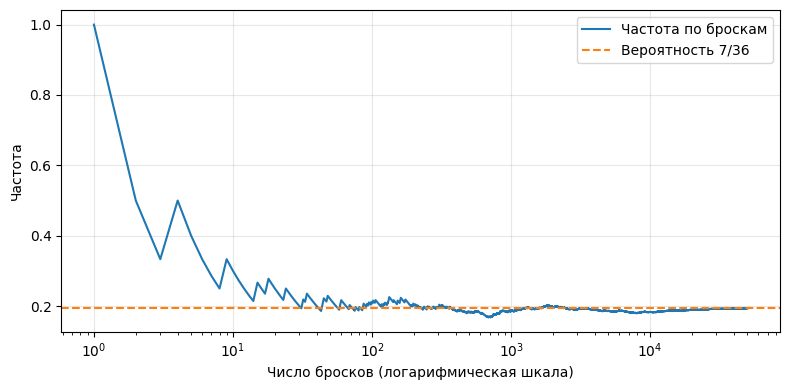

In [4]:
plt.figure(figsize=(8, 4))
plt.plot(broski, chastota, label='Частота по броскам')
plt.axhline(p, color='tab:orange', linestyle='--', label='Вероятность 7/36')
plt.xscale('log')
plt.xlabel('Число бросков (логарифмическая шкала)')
plt.ylabel('Частота')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()